In [ ]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from desmin_reconstruction.plotting import save_panel
from IPython.display import display, SVG
from matplotlib.colors import Normalize, TwoSlopeNorm
from matplotlib.offsetbox import AnchoredOffsetbox, DrawingArea, HPacker, TextArea
from matplotlib.patches import Rectangle
from matplotlib.ticker import FormatStrFormatter, MaxNLocator


PROTEINS = ("desmin", "actinin")
COLOR_DICT = {"desmin": "#CC3311", "actinin": "#009988"}
LABEL_DICT = {"desmin": "Desmin", "actinin": "α-actinin"}

In [ ]:
def load_angular_h(path):
    """Load saved means, respecting their existing array orientation."""
    with np.load(path, allow_pickle=False) as data:
        theta = np.array(data["bin_theta"], dtype=float, copy=True)
        phi = np.array(data["bin_phi"], dtype=float, copy=True)
        means = {p: np.array(data[f"H_{p}"], dtype=float, copy=True) for p in PROTEINS}
    shape = means[PROTEINS[0]].shape
    if len(shape) != 2 or 0 in shape:
        raise ValueError("H_desmin and H_actinin must be nonempty 2D mean arrays.")
    for protein, H in means.items():
        if H.shape != shape:
            raise ValueError("Both proteins must use the same angular bin grid.")
        if not np.isfinite(H).any():
            raise ValueError(f"H_{protein} contains no finite values.")
    nphi, ntheta = shape
    if not np.isfinite(theta).all() or not np.isfinite(phi).all():
        raise ValueError("Angular coordinates must be finite.")
    if theta.ndim == phi.ndim == 1:
        if (len(phi), len(theta)) not in (shape, (nphi + 1, ntheta + 1)):
            raise ValueError(
                f"H shape {shape} does not match bin_phi/bin_theta lengths "
                f"{len(phi)}/{len(theta)}. Expected rows=phi, columns=theta; "
                "the loader does not transpose data automatically."
            )
        if np.any(np.diff(theta) <= 0) or np.any(np.diff(phi) <= 0):
            raise ValueError("1D angular coordinates must be strictly increasing.")
    elif theta.ndim == phi.ndim == 2:
        if theta.shape != phi.shape or theta.shape not in (
            shape,
            (nphi + 1, ntheta + 1),
        ):
            raise ValueError("2D bin grids must match each other and the mean arrays.")
    else:
        raise ValueError("Provide two 1D bin arrays or two 2D coordinate grids.")
    return (theta, phi), means


def make_shared_norm(means, *, scale="symmetric", symmetric_limit=None):
    """Create one normalization for both proteins, always centered on zero.

    symmetric: one linear slope for negative and positive values; equal
        magnitudes occupy equal distances from the colormap midpoint.
    two_slope: use the pooled observed negative and positive extrema as the
        endpoints. Each sign occupies half the colormap, so color change per
        H unit differs between signs when their ranges differ. This is a
        piecewise-linear display mapping and should be described if used.

    No values are clipped. symmetric_limit can fix a common scale across
    figures, but must contain every finite value.
    """
    finite = [H[np.isfinite(H)] for H in means.values()]
    low = min(float(v.min()) for v in finite)
    high = max(float(v.max()) for v in finite)
    maximum = max(abs(low), abs(high))
    if scale == "symmetric":
        limit = (maximum or 1.0) if symmetric_limit is None else float(symmetric_limit)
        if not np.isfinite(limit) or limit <= 0 or limit < maximum:
            raise ValueError(
                "symmetric_limit must be positive and contain all finite H values."
            )
        return Normalize(vmin=-limit, vmax=limit)
    if scale == "two_slope":
        if symmetric_limit is not None:
            raise ValueError("symmetric_limit applies only to scale='symmetric'.")
        if low < 0 < high:
            return TwoSlopeNorm(vmin=low, vcenter=0.0, vmax=high)
        # A missing sign has no observed range to stretch; use symmetry.
        return Normalize(vmin=-(maximum or 1.0), vmax=(maximum or 1.0))
    raise ValueError("scale must be 'symmetric' or 'two_slope'.")


def _protein_title(ax, name, color, *, style, fontsize, pad):
    if style == "colored":
        ax.set_title(
            name, color=color, fontsize=fontsize, fontweight="semibold", pad=pad
        )
    elif style == "swatch":
        square = DrawingArea(9, 9, 0, 0)
        square.add_artist(Rectangle((0, 0), 9, 9, facecolor=color, edgecolor="none"))
        text = TextArea(
            name,
            textprops={
                "color": "black",
                "fontsize": fontsize,
                "fontweight": "semibold",
            },
        )
        packed = HPacker(children=[square, text], align="center", pad=0, sep=6)
        header = AnchoredOffsetbox(
            loc="lower center",
            child=packed,
            frameon=False,
            pad=0,
            borderpad=pad / fontsize,
            bbox_to_anchor=(0.5, 1.0),
            bbox_transform=ax.transAxes,
            prop={"size": fontsize},
        )
        header.set_clip_on(False)
        ax.add_artist(header)
    else:
        raise ValueError("title_style must be 'colored' or 'swatch'.")


def make_angular_h_panel(
    path,
    *,
    figsize=(8.2, 3.6),
    cmap=None,
    scale="symmetric",
    symmetric_limit=None,
    title_style="colored",
    colors=None,
    labels=None,
    title_size=14,
    label_size=13,
    tick_size=11,
    colorbar_label_size=13,
    colorbar_tick_size=11,
    title_pad=9,
    tick_pad=5,
    panel_gap=0.07,
    radius_um=None,
    font_family="DejaVu Sans",
):
    """Read the NPZ and return (fig, axes, colorbar).

    The default cmocean.balance uses blue / off-white / red, with off-white
    at zero. Set cmap=cmocean.cm.diff for a blue/brown alternative.
    scale='symmetric' retains equal scaling above and below zero.
    title_style='swatch' places a square directly beside a black title.
    panel_gap controls constrained-layout wspace (fraction of subplot widths).
    radius_um optionally adds a heading; no radius is inferred from the NPZ.
    NaN/inf bins are shown gray, not as zero. Rasterized mesh, vector axes.
    """
    bins, means = load_angular_h(path)
    norm = make_shared_norm(means, scale=scale, symmetric_limit=symmetric_limit)
    if cmap is None:
        import cmocean

        cmap = cmocean.cm.balance
    elif isinstance(cmap, str):
        cmap = mpl.colormaps[cmap]
    cmap = cmap.copy()
    cmap.set_bad("#D0D0D0")
    colors = COLOR_DICT if colors is None else colors
    labels = LABEL_DICT if labels is None else labels

    with (
        plt.style.context("default"),
        mpl.rc_context(
            {
                "font.family": font_family,
                "font.size": tick_size,
                "axes.linewidth": 0.7,
                "axes.edgecolor": "#444444",
                "figure.facecolor": "white",
                "axes.facecolor": "white",
                "text.usetex": False,
            }
        ),
    ):
        fig, axes = plt.subplots(
            1,
            2,
            figsize=figsize,
            sharex=True,
            sharey=True,
            layout="constrained",
        )
        fig.get_layout_engine().set(w_pad=0.04, h_pad=0.04, wspace=panel_gap)
        for ax, protein in zip(axes, PROTEINS):
            mesh = ax.pcolormesh(
                *bins,
                np.ma.masked_invalid(means[protein]),
                cmap=cmap,
                norm=norm,
                shading="auto",
                antialiased=False,
                edgecolors="none",
                linewidth=0,
                rasterized=True,
            )
            ax.set_xticks(
                [-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi],
                [r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"],
            )
            ax.set_yticks(
                [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4, np.pi],
                ["0", r"$\pi/4$", r"$\pi/2$", r"$3\pi/4$", r"$\pi$"],
            )
            ax.set_xlim(-np.pi, np.pi)
            ax.set_ylim(0, np.pi)
            ax.tick_params(
                direction="out", length=3, width=0.7, pad=tick_pad, labelsize=tick_size
            )
            ax.grid(False)
            # Keep X tick labels centered; move the boundary Y label upward.
            for value, label in zip(ax.get_yticks(), ax.get_yticklabels()):
                if value == 0:
                    label.set_va("bottom")
                elif np.isclose(value, np.pi):
                    label.set_va("top")
            _protein_title(
                ax,
                labels[protein],
                colors[protein],
                style=title_style,
                fontsize=title_size,
                pad=title_pad,
            )

        fig.supxlabel(r"Azimuthal angle $\theta$ (rad)", fontsize=label_size)
        axes[0].set_ylabel(
            r"Polar angle $\varphi$ (rad)", fontsize=label_size, labelpad=7
        )
        cbar = fig.colorbar(
            mesh, ax=axes.tolist(), pad=0.025, fraction=0.045, aspect=24
        )

        cbar.set_label(
            r"$H_{3D}(\theta, \phi; r)$", fontsize=colorbar_label_size, labelpad=7
        )
        ticks = MaxNLocator(nbins=6).tick_values(norm.vmin, norm.vmax)
        tolerance = 1e-10 * (norm.vmax - norm.vmin)
        ticks = ticks[
            (ticks >= norm.vmin - tolerance) & (ticks <= norm.vmax + tolerance)
        ]
        ticks = np.clip(ticks, norm.vmin, norm.vmax)
        cbar.set_ticks(np.unique(np.r_[ticks, 0.0]))
        cbar.ax.yaxis.set_major_formatter(FormatStrFormatter("%g"))
        cbar.ax.tick_params(labelsize=colorbar_tick_size, length=3, width=0.7, pad=4)
        cbar.outline.set_linewidth(0.6)
        # A small mark makes the reference value easy to find on the legend.
        cbar.ax.axhline(0, color="#555555", lw=0.6, alpha=0.7)
        if radius_um is not None:
            fig.suptitle(
                r"Angular Ripley's $H$ function: "
                + rf"$r={float(radius_um):g}\,\mathrm{{\mu m}}$",
                fontsize=label_size,
            )
    return fig, axes, cbar

In [ ]:
fig, axes, cbar = make_angular_h_panel(
    "../../source_data/fig_2/2f.npz",
    figsize=(8.2, 3.6),
    title_size=14,
    label_size=14,
    tick_size=13,
    colorbar_label_size=14,
    radius_um=1.0,
)

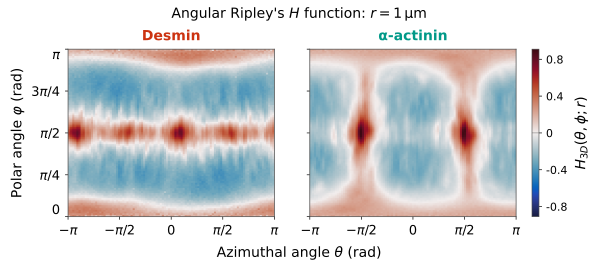

In [26]:
savepath = "../../figures/2f"
save_panel(fig, savepath, formats=("svg",))
display(SVG(filename=str(savepath + ".svg")))
plt.close(fig)